# Figure 5

Panels A, C and D: ΔSNR of the medulla pairs with respect to the optimal partner in the generalized filter space, SNR of the medulla pairs by circuit type, and z-scored SNR histograms. Panels E–G are produced by `Fig5_2_LPTC_Silencing_Serbe2016.ipynb`.

**Precomputed.** `GeneralizedLattice_MedullaEnsemble_WeakLobe_pool100Hz_matchedP_ref1.6_dtfix.npz`: SNR of the 30 filters of each medulla type paired with each other and with every filter of the generalized filter space, for k = −1.6 and for white noise of matched power (8 bands, 0.01–100 Hz). Set `PATH_PRECOMPUTED` to its folder.

**SNR code.** All functions to compute the SNR (Eqs. 20, 21) are in `Fig3_1_SNR_vs_TemporalDiversity.ipynb`; its `snr_circuit` computes the SNR of any circuit, so the precomputed SNR can be reproduced from there.

**Fit parameters.** `FitParameters/` contains the parameters of Eq. 4 fitted to the measured mean filters and the filters of the generalized filter space.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Rectangle
from matplotlib.ticker import MaxNLocator

matplotlib.rcParams['font.family']      = 'sans-serif'
matplotlib.rcParams['font.sans-serif']  = ['Arial']
matplotlib.rcParams['font.size']        = 12
matplotlib.rcParams['pdf.fonttype']     = 42
matplotlib.rcParams['ps.fonttype']      = 42
matplotlib.rcParams['axes.titlesize']   = 12
matplotlib.rcParams['axes.labelsize']   = 12
matplotlib.rcParams['xtick.labelsize']  = 12
matplotlib.rcParams['ytick.labelsize']  = 12
matplotlib.rcParams['legend.fontsize']  = 12
matplotlib.rcParams['axes.linewidth']   = 1.2
matplotlib.rcParams['figure.dpi']       = 130
matplotlib.rcParams['savefig.dpi']      = 300
matplotlib.rcParams['hatch.linewidth']  = 0.5
matplotlib.rcParams['mathtext.fontset'] = 'custom'
matplotlib.rcParams['mathtext.rm']      = 'Arial'
matplotlib.rcParams['mathtext.it']      = 'Arial:italic'

# Paths
PATH_PRECOMPUTED = Path('/Users/luisaramirez/Documents/Documentos/PostDoc/Mainz_Sillies/Research/'
                        'Julijana_Marion/Research/Codes/Optimization/PNAS_revisions/Filters')
PATH_PARAMS      = Path('FitParameters')
PATH_PDF         = Path('Pdf_figures')
PATH_PDF.mkdir(exist_ok=True)

In [2]:
COLOR_COLUMN  = {'multi': '#662c67', 'single': '#e9bcc2'}      # purple, light pink
COLUMN_LABEL  = {'multi': 'Multi column', 'single': 'Single column'}
INSET_LABEL   = {'multi': 'Multi col', 'single': 'Single col'}
COLUMN_DRAW   = ['multi', 'single']
COLOR_PATHWAY = {'ON': '#f4eb60', 'OFF': '#cf5d3d'}
COLOR_DOT     = ('#cf5d3d', '#de9145')
SNR_GREYS     = matplotlib.colors.ListedColormap(plt.cm.Greys(np.linspace(0.08, 1.0, 256)))

# medulla inputs to T4 (ON) and T5 (OFF): partners top down, fixed filters left to right
MEDULLA_ROWS    = ['Tm3', 'Mi1', 'Mi4', 'Mi9', 'Tm4', 'Tm2', 'Tm1', 'Tm9']
MEDULLA_COLS    = MEDULLA_ROWS[::-1]
N_MED, N_ON     = len(MEDULLA_ROWS), 4
PATHWAY_OF      = {ct: ('ON' if i < N_ON else 'OFF') for i, ct in enumerate(MEDULLA_ROWS)}
DOUBLE_POLARITY = ['Mi1', 'Tm3', 'Tm1', 'Tm2', 'Tm4']
COLUMN_OF       = {'Mi9': 'C1', 'Mi1': 'C2', 'Tm3': 'C2', 'Mi4': 'C3',
                   'Tm9': 'C1', 'Tm1': 'C2', 'Tm2': 'C2', 'Tm4': 'C2'}
C_PAIRS = [('Mi9', 'Mi4'), ('Mi1', 'Tm3'), ('Tm2', 'Tm1'), ('Tm1', 'Tm4'), ('Tm2', 'Tm4'),
           ('Mi1', 'Mi4'), ('Mi1', 'Mi9'), ('Tm3', 'Mi9'), ('Tm3', 'Mi4'), ('Tm1', 'Tm9'),
           ('Tm2', 'Tm9'), ('Tm4', 'Tm9')]

# naturalistic stimulus (k = -1.6) and white noise matched to its in-band variance
STIMULI = ('natural', 'white')
SNR_KEY = {'natural': 'a1.6', 'white': 'a0'}


def filter_function(t, tau1, tau2, rho_):
    # Eq. 4 with beta1 = 4, beta2 = 3 and rho = rho_ - 1, peak-normalized
    rho = rho_ - 1
    h = t**3 * (np.exp(-t / tau1) / tau1**4) + t**2 * (rho * np.exp(-t / tau2) / tau2**3)
    return h / np.max(np.abs(h))


T_SHARP = np.arange(1e-4, 3.0, 1e-4)        # s


def peak_flatness(pars):
    # width at 90% of the peak over the time to the peak
    h = filter_function(T_SHARP, *pars)
    h = h / h.max()
    return float((h >= 0.90).sum()) * float(T_SHARP[1] - T_SHARP[0]) / float(T_SHARP[int(np.argmax(h))])


def pair_class(a, b):
    return 'single' if COLUMN_OF[a] == COLUMN_OF[b] else 'multi'


def pair_name(a, b):
    return f'{a}-{b}'

## Generalized filter space and pair SNR

In [3]:
fit_params = {}
with open(PATH_PARAMS / 'MeasuredFilters_FitParameters.txt') as fh:
    for line in fh:
        if not line.startswith('#'):
            ct, *p = line.split()
            fit_params[ct] = np.array(p, float)

# one filter per cell of the generalized filter space
lattice = np.load(PATH_PARAMS / 'GeneralizedLattice_WeakLobe.npz')
pars, A, tau_L = lattice['rep_pars'], lattice['rep_A'], lattice['rep_tau']
row_of_cell = {(int(k), int(m)): i for i, (k, m) in enumerate(zip(lattice['rep_k'], lattice['rep_m']))}
row_of_type = {ct: int(np.flatnonzero((pars == fit_params[ct]).all(axis=1))[0]) for ct in MEDULLA_ROWS}

# fly-like filters with tau_L >= 0.15 s, A >= 0 and a sharp peak
TAU_MIN, A_MIN, SHARP_MAX = 0.15, 0.0, 0.70
SHARP_KEEP = {(8, 23), (9, 25), (15, 40), (7, 21), (12, 34), (9, 26), (11, 31), (13, 36), (10, 28),
              (12, 33), (7, 20), (13, 35), (12, 32), (10, 27), (15, 39), (13, 34), (7, 19), (10, 26),
              (8, 21), (5, 18)}
SHARP_DROP = {(9, 24)}
sharp = np.array([peak_flatness(p) <= SHARP_MAX for p in pars])
for cell in SHARP_KEEP:
    sharp[row_of_cell[cell]] = True
for cell in SHARP_DROP:
    sharp[row_of_cell[cell]] = False
population = lattice['rep_ok'] & (tau_L >= TAU_MIN) & (A >= A_MIN) & sharp

ens        = np.load(PATH_PRECOMPUTED / 'GeneralizedLattice_MedullaEnsemble_WeakLobe_pool100Hz_matchedP_ref1.6_dtfix.npz')
type_index = {str(ct): i for i, ct in enumerate(ens['types'])}
snr_pair   = {s: ens[f'snr_pair_{SNR_KEY[s]}'] for s in STIMULI}   # (type, type, draw)
snr_lat    = {s: ens[f'snr_lat_{SNR_KEY[s]}'] for s in STIMULI}    # (type, draw, lattice cell)


def gmean_draws(v):
    return np.exp(np.log(v).mean(axis=-1))


def pair_snr(stim, a, b):
    return float(gmean_draws(snr_pair[stim][type_index[a], type_index[b]]))


def optimum_snr(stim, ct):
    # SNR of ct with its best partner in the generalized filter space, ct's own cell excluded
    snr = np.where(population, gmean_draws(snr_lat[stim][type_index[ct]].T), -np.inf)
    snr[row_of_type[ct]] = -np.inf
    return float(snr.max())


snr_med   = {s: np.array([[pair_snr(s, ct, pt) for ct in MEDULLA_COLS] for pt in MEDULLA_ROWS])
             for s in STIMULI}
snr_opt   = {s: np.array([optimum_snr(s, ct) for ct in MEDULLA_COLS]) for s in STIMULI}
delta_snr = {s: 100 * (1 - snr_med[s] / snr_opt[s][None, :]) for s in STIMULI}   # %

C_SNR   = {s: np.array([pair_snr(s, *p) for p in C_PAIRS]) for s in STIMULI}
C_CLASS = np.array([pair_class(*p) for p in C_PAIRS])

## Fig. 5A

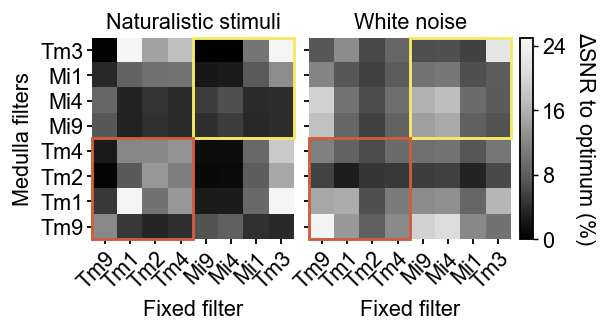

Naturalistic stimuli
  Tm9  best partner Tm2  Delta SNR  0.68%, multi-column
  Tm1  best partner Tm9  Delta SNR  4.96%, multi-column
  Tm2  best partner Tm9  Delta SNR  3.45%, multi-column
  Tm4  best partner Tm9  Delta SNR  4.23%, multi-column
  Mi9  best partner Tm3  Delta SNR -0.01%, multi-column
  Mi4  best partner Tm3  Delta SNR -0.00%, multi-column
  Mi1  best partner Mi9  Delta SNR  3.63%, multi-column
  Tm3  best partner Mi9  Delta SNR  4.01%, multi-column
  largest Delta SNR of a combined-polarity pair: 4.96%
White noise
  Tm9  best partner Tm2  Delta SNR  5.67%, multi-column
  Tm1  best partner Tm2  Delta SNR  2.81%, single-column
  Tm2  best partner Tm4  Delta SNR  6.50%, single-column
  Tm4  best partner Tm2  Delta SNR  4.97%, single-column
  Mi9  best partner Tm3  Delta SNR  6.60%, multi-column
  Mi4  best partner Tm3  Delta SNR  6.79%, multi-column
  Mi1  best partner Tm3  Delta SNR  5.65%, single-column
  Tm3  best partner Mi9  Delta SNR  6.94%, multi-column
  largest De

In [4]:
B_MAP, B_GAP_IN = 1.55, 0.12
B_L, B_R, B_BOT, B_TOP = 0.95, 0.85, 0.85, 0.32
B_TITLE   = {'natural': 'Naturalistic stimuli', 'white': 'White noise'}
DSNR_VMAX = 25.0

W, H = B_L + 2 * B_MAP + B_GAP_IN + B_R, B_BOT + B_MAP + B_TOP
Fig = plt.figure(figsize=(W, H))
for i, s in enumerate(STIMULI):
    x0 = B_L + i * (B_MAP + B_GAP_IN)
    ax = Fig.add_axes([x0 / W, B_BOT / H, B_MAP / W, B_MAP / H])
    im = ax.imshow(delta_snr[s], cmap=SNR_GREYS.reversed(), vmin=0.0, vmax=DSNR_VMAX,
                   origin='upper', aspect='auto', interpolation='nearest')
    ax.add_patch(Rectangle((N_ON - 0.5, -0.5), N_MED - N_ON, N_ON, facecolor='none',
                           edgecolor=COLOR_PATHWAY['ON'], linewidth=1.6, zorder=6, clip_on=False))
    ax.add_patch(Rectangle((-0.5, N_ON - 0.5), N_ON, N_MED - N_ON, facecolor='none',
                           edgecolor=COLOR_PATHWAY['OFF'], linewidth=1.6, zorder=6, clip_on=False))
    ax.set_xticks(range(N_MED))
    ax.set_xticklabels(MEDULLA_COLS, rotation=45, ha='right', rotation_mode='anchor')
    ax.set_yticks(range(N_MED))
    ax.set_yticklabels(MEDULLA_ROWS if i == 0 else [])
    ax.tick_params(length=2.5, width=1.0, pad=2.5)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xlabel('Fixed filter')
    if i == 0:
        ax.set_ylabel('Medulla filters')
    ax.set_title(B_TITLE[s], pad=5)
cax = Fig.add_axes([(x0 + B_MAP + 0.07) / W, B_BOT / H, 0.1 / W, B_MAP / H])
cb  = Fig.colorbar(im, cax=cax)
cb.locator = MaxNLocator(nbins=4); cb.update_ticks()
cb.outline.set_linewidth(1.0)
cax.tick_params(length=2.5, pad=2.5)
cb.set_label(r'$\Delta$SNR to optimum (%)', rotation=270, va='bottom')
Fig.savefig(PATH_PDF / 'Fig5A_DeltaSNR_LatticeOptimum.pdf', transparent=True)
plt.show()

# best partner within the pathway of each fixed filter
for s in STIMULI:
    print(B_TITLE[s])
    for c, ct in enumerate(MEDULLA_COLS):
        rows = [r for r, pt in enumerate(MEDULLA_ROWS) if pt != ct and PATHWAY_OF[pt] == PATHWAY_OF[ct]]
        best = MEDULLA_ROWS[min(rows, key=lambda r: delta_snr[s][r, c])]
        print(f'  {ct:4s} best partner {best:4s} Delta SNR {delta_snr[s][MEDULLA_ROWS.index(best), c]:5.2f}%, '
              f'{pair_class(ct, best)}-column')
    combined = [delta_snr[s][r, c] for c, ct in enumerate(MEDULLA_COLS) for r, pt in enumerate(MEDULLA_ROWS)
                if PATHWAY_OF[pt] == PATHWAY_OF[ct] and (pt in DOUBLE_POLARITY) != (ct in DOUBLE_POLARITY)]
    print(f'  largest Delta SNR of a combined-polarity pair: {max(combined):.2f}%')

## Fig. 5C

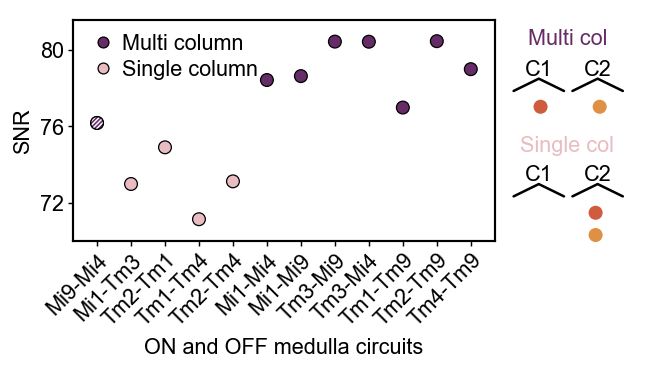

In [5]:
PT_TICK_ORIG = 7.4                       # pt, text size in print
SCALE        = 12.0 / PT_TICK_ORIG

# panel blocks and axes in PDF points of the printed page (x0, y_top, x1, y_bottom)
BLOCK = {'C': ( 89.0, 300.0, 322.0, 432.0),
         'D': (318.0, 300.0, 500.0, 434.0)}
AXES  = {'C':    (121.4, 310.5, 265.3, 385.9),
         'C_in': (268.0, 308.0, 314.0, 390.0),
         'D1':   (350.4, 311.5, 415.1, 410.2),
         'D2':   (433.0, 311.7, 497.0, 410.0)}
C_LEGEND  = (124.8, 312.2)
D_TITLE_Y = 321.0


def figsize_of(block):
    x0, y0, x1, y1 = BLOCK[block]
    return ((x1 - x0) * SCALE / 72.0, (y1 - y0) * SCALE / 72.0)


def rect_in(block, x0, y_top, x1, y_bot):
    bx0, by0, bx1, by1 = BLOCK[block]
    W, H = bx1 - bx0, by1 - by0
    return [(x0 - bx0) / W, (by1 - y_bot) / H, (x1 - x0) / W, (y_bot - y_top) / H]


def point_in(block, x, y):
    bx0, by0, bx1, by1 = BLOCK[block]
    return ((x - bx0) / (bx1 - bx0), (by1 - y) / (by1 - by0))


MARKER_S     = 50
HATCH_PAIRS  = {frozenset(('Mi9', 'Mi4'))}
HATCH        = '////'
HATCH_MARKER = '//////////'
HATCH_LW     = 0.8
HATCH_COLOR  = 'white'


def hatched(p):
    return frozenset(p) in HATCH_PAIRS


def draw_inset(Fig, block, rect=AXES['C_in']):
    # column schematic, in page coordinates
    x0, y0, x1, y1 = rect
    ax = Fig.add_axes(rect_in(block, *rect))
    ax.set_xlim(x0, x1); ax.set_ylim(y1, y0)
    ax.set_axis_off()

    def brace(xc, y_top, half=8.6, h=4.2):
        ax.plot([xc - half, xc, xc + half], [y_top + h, y_top, y_top + h], color='k', lw=1.4,
                solid_capstyle='round', solid_joinstyle='round', clip_on=False)

    def dot(x, y, c, r=2.4):
        ax.add_patch(Circle((x, y), r, facecolor=c, edgecolor='none', clip_on=False))

    for cls, y_txt, y_c, y_br, dots in (
            ('multi',  319.0, 329.4, 330.6, [(281.0, 340.2, 0), (301.2, 340.2, 1)]),
            ('single', 355.4, 365.4, 366.6, [(299.8, 376.4, 0), (299.8, 384.0, 1)])):
        ax.text(290.2, y_txt, INSET_LABEL[cls], color=COLOR_COLUMN[cls], ha='center',
                va='baseline')
        for xc, lab in ((280.4, 'C1'), (300.5, 'C2')):
            ax.text(xc, y_c, lab, ha='center', va='baseline')
            brace(xc, y_br)
        for x, y, i in dots:
            dot(x, y, COLOR_DOT[i])
    return ax


Fig = plt.figure(figsize=figsize_of('C'))
ax  = Fig.add_axes(rect_in('C', *AXES['C']))
y   = C_SNR['natural']
is_hatched = np.array([hatched(p) for p in C_PAIRS])
colors = np.array([COLOR_COLUMN[k] for k in C_CLASS])
x   = np.arange(len(C_PAIRS))
ax.scatter(x, y, s=MARKER_S, c=colors, edgecolor='k', linewidth=0.7, zorder=3, clip_on=False)
# hatch as an edgeless layer, contour redrawn on top
with matplotlib.rc_context({'hatch.linewidth': HATCH_LW}):
    ax.scatter(x[is_hatched], y[is_hatched], s=MARKER_S, facecolors='none', edgecolors=HATCH_COLOR,
               linewidths=0, hatch=HATCH_MARKER, zorder=3.1, clip_on=False)
ax.scatter(x[is_hatched], y[is_hatched], s=MARKER_S, facecolors='none', edgecolors='k', linewidths=0.7,
           zorder=3.2, clip_on=False)
ax.set_xticks(range(len(C_PAIRS)))
ax.set_xticklabels([pair_name(*p) for p in C_PAIRS], rotation=45, ha='right',
                   rotation_mode='anchor')
ax.set_xlim(-0.7, len(C_PAIRS) - 0.3)
pad = 0.12 * (y.max() - y.min())
ax.set_ylim(y.min() - pad, y.max() + pad)
ax.yaxis.set_major_locator(MaxNLocator(nbins=3))
ax.tick_params(length=2.5, pad=2.5)
ax.set_ylabel('SNR')
ax.set_xlabel('ON and OFF medulla circuits')
ax.legend(handles=[Line2D([], [], marker='o', ls='none', markerfacecolor=COLOR_COLUMN[k],
                          markeredgecolor='k', markeredgewidth=0.7,
                          markersize=0.85 * np.sqrt(MARKER_S), label=COLUMN_LABEL[k])
                   for k in COLUMN_DRAW],
          loc='upper left', bbox_to_anchor=point_in('C', *C_LEGEND),
          bbox_transform=Fig.transFigure, frameon=False, handlelength=1.0,
          handletextpad=0.4, labelspacing=0.3, borderaxespad=0.0)
draw_inset(Fig, 'C')
Fig.savefig(PATH_PDF / 'Fig5C_SNRbyCircuit.pdf', transparent=True)
plt.show()

## Fig. 5D

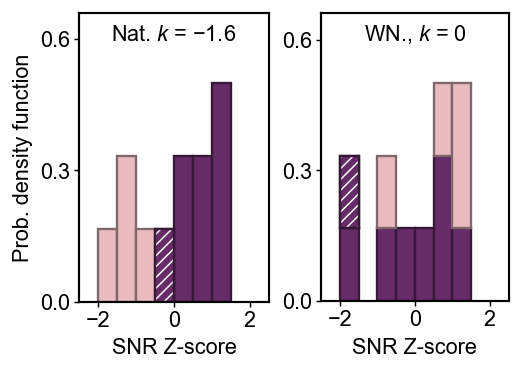

In [6]:
Z_BINS   = np.arange(-2.5, 2.51, 0.5)
D_TITLE  = {'natural': r'Nat. $k$ = −1.6', 'white': r'WN., $k$ = 0'}
BAR_EDGE = (0.45, 1.3)                   # darkening of the contour, line width


def bar_style(color):
    rgb = np.array(matplotlib.colors.to_rgb(color))
    return dict(facecolor=(*rgb, 1.0), edgecolor=tuple(rgb * (1 - BAR_EDGE[0])),
                linewidth=BAR_EDGE[1])


def z_bins(z, bins=Z_BINS):
    # widened by whole bins if a z-score falls outside
    w = bins[1] - bins[0]
    lo, hi = bins[0], bins[-1]
    while z.min() < lo:
        lo -= w
    while z.max() >= hi:
        hi += w
    return np.arange(lo, hi + w / 2, w)


Fig = plt.figure(figsize=figsize_of('D'))
for i, (s, key) in enumerate(zip(STIMULI, ('D1', 'D2'))):
    ax = Fig.add_axes(rect_in('D', *AXES[key]))
    y  = C_SNR[s]
    z  = (y - y.mean()) / y.std()
    bins  = z_bins(z)
    width = bins[1] - bins[0]
    x     = 0.5 * (bins[1:] + bins[:-1])
    total = np.histogram(z, bins=bins)[0] / (len(z) * width)
    bottom = np.zeros(len(x))
    is_hatched = np.array([hatched(p) for p in C_PAIRS])
    for k in COLUMN_DRAW:                   # stacked by circuit type, hatched pairs on top
        for sel, hatch in ((~is_hatched, None), (is_hatched, HATCH)):
            h = np.histogram(z[(C_CLASS == k) & sel], bins=bins)[0] / (len(z) * width)
            n = h > 0
            if not n.any():
                continue
            style = bar_style(COLOR_COLUMN[k])
            ax.bar(x[n], h[n], width=width, bottom=bottom[n], zorder=2, **style)
            if hatch:
                with matplotlib.rc_context({'hatch.linewidth': HATCH_LW}):
                    ax.bar(x[n], h[n], width=width, bottom=bottom[n], zorder=2.1,
                           facecolor='none', edgecolor=HATCH_COLOR, linewidth=0, hatch=hatch)
                ax.bar(x[n], h[n], width=width, bottom=bottom[n], zorder=2.2,
                       facecolor='none', edgecolor=style['edgecolor'], linewidth=style['linewidth'])
            bottom += h
    ax.set_xlim(bins[0], bins[-1])
    ax.set_xticks([t for t in (-2, 0, 2) if bins[0] <= t <= bins[-1]])
    ax.set_ylim(0, 1.32 * total.max())
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3, steps=[1, 2, 3, 6, 10]))
    ax.tick_params(length=2.5, pad=2.5)
    ax.set_xlabel('SNR Z-score')
    if i == 0:
        ax.set_ylabel('Prob. density function')
    Fig.text(*point_in('D', 0.5 * (AXES[key][0] + AXES[key][2]), D_TITLE_Y), D_TITLE[s],
             ha='center', va='baseline')
Fig.savefig(PATH_PDF / 'Fig5D_SNRHistograms.pdf', transparent=True)
plt.show()